Loading the UID 2021 dataset.
Extracting:
The identifiers **('Name')** for individual samples **(stored in data_address).**
The corresponding quality scores **('MOS')** for these samples **(stored in target).**


In [1]:
import pandas as pd 
data_info = pd.read_csv('mos.csv',encoding='utf-8')

data_address = data_info['Name']
target = data_info['MOS']


### Summary of Columns
The final CSV file has the following columns:

**lum_l**: contrast variability.

**br_ent**: Entropy of the grayscale image.

**freq1, freq3**: Frequency-domain sharpness at two cutoff frequencies.

**cannysharp1**: Canny edge detector-based sharpness.

**AL_adh1, AR_adh1, BL_adh1, BR_adh1, ..., AL_adh3, AR_adh3, BL_adh3, BR_adh3** : AGGD parameters for 3 scales.

**Ap_h1, sg_h1, ..., Ap_h3, sg_h3**: GGD parameters for 3 scales.

**L_mean, L_variance, L_skewness, ..., b_mean, b_variance, b_skewness:** Color moments for L, a, and b channels.

### Purpose of Features

#### These features collectively measure various aspects of image quality, including:

* Luminance and contrast: Indicate brightness and local variation.
* Sharpness: Quantifies the clarity and detail of edges and textures.
* Texture complexity: Captures randomness via entropy.
* Frequency domain properties: Provide sharpness insights using high-pass filters.
* Statistical properties: AGGD and GGD parameters model image intensity distributions.
* Color properties: Color moments describe the distribution of colors in the Lab color space.

In [ ]:
import numpy as np
import cv2
from skimage import filters, metrics
from skimage import io, img_as_float, color
from skimage.filters import gaussian, sobel,laplace
from skimage.restoration import denoise_tv_chambolle
from skimage import io, color, morphology, exposure
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage import img_as_ubyte
from skimage.feature import local_binary_pattern
import matplotlib.pyplot as plt
from scipy.special import gamma
from scipy.optimize import minimize
import csv
import pywt

def local_contrast_luminance(image, block_size=32):
    # Convert the image to float32 if it is not already
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8)
    
    # Convert to grayscale if the image is in RGB format
    if len(image.shape) == 3:
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray_image = image

    height, width = gray_image.shape

    contrast_values = []
    local_lum = []
    # Iterate over each block
    for y in range(0, height, block_size):
        for x in range(0, width, block_size):
            # Define the block
            block = gray_image[y:y+block_size, x:x+block_size]
            # Check if the block is valid
            if block.shape[0] != block_size or block.shape[1] != block_size:
                continue
            
            # Compute mean luminance
            block_mean = np.mean(block)
            # Compute local contrast (standard deviation in this case)
            contrast = np.std(block)
            contrast_values.append(contrast)

    # Return the average contrast across all blocks
    return np.var(contrast_values)


def image_entropy(image):
    # Convert image to grayscale if it's not already
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Ensure the image is in uint8 format
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8)

    # Calculate histogram
    hist = cv2.calcHist([image], [0], None, [256], [0, 256])
    hist = hist / hist.sum()  # Normalize the histogram

    # Calculate entropy
    entropy = -np.sum(hist * np.log2(hist + 1e-10))  # Add small value to avoid log(0)

    return entropy

# contrast 
def apply_ahe(image, clip_limit=0.05):# adaptive histogram 
    ahe_image = exposure.equalize_adapthist(image, clip_limit=clip_limit)
    return ahe_image


# Function to calculate MSCN coefficients at multiple scales
def calculate_mscn_multi_scale(image, scales):
    mscn_coeffs = []
    
    for scale in scales:
        sigma = scale * 7 / 6
        mu = gaussian(image, sigma=sigma)
        var = gaussian(image**2, sigma=sigma) - mu**2
        sigma = np.sqrt(np.maximum(var, 1e-10))  # Using np.maximum to avoid negative values
        C = 1.0 / 255  # Small constant to prevent division by zero
        mscn = (image - mu) / (sigma + C)
        mscn_coeffs.append(mscn)
    
    return mscn_coeffs

# Function to estimate AGGD parameters from a vector
def estimate_aggd_params(vec):
    left_std = np.sqrt(np.mean((vec[vec < 0])**2))
    right_std = np.sqrt(np.mean((vec[vec > 0])**2))
    gamma_hat = left_std / right_std if right_std != 0 else 0
    
    rhat = (np.mean(np.abs(vec)))**2 / np.mean(vec**2)
    rhat_norm = (gamma(2 / np.mean(np.abs(vec))) / gamma(1 / np.mean(np.abs(vec))))**2
    
    agg_param = np.zeros(2)
    
    agg_param[0] = np.sqrt((rhat / rhat_norm) * gamma_hat)
    agg_param[1] = np.sqrt((rhat / rhat_norm) / gamma_hat)
    
    return agg_param

# Function to fit AGGD to MSCN coefficients
def fit_aggd(mscn):
    alpha = estimate_aggd_params(mscn)
    beta_l = np.sqrt(np.mean((mscn[mscn < 0])**2))
    beta_r = np.sqrt(np.mean((mscn[mscn > 0])**2))
    return alpha[0], alpha[1], beta_l**2, beta_r**2
#ggd method : 
def estimate_ggd_params(vec):
    def ggd_loss(params, vec):
        alpha, sigma = params
        beta = sigma * np.sqrt(gamma(1 / alpha) / gamma(3 / alpha))
        likelihoods = (alpha / (2 * beta * gamma(1 / alpha))) * np.exp(-(np.abs(vec) / beta) ** alpha)
        return -np.sum(np.log(likelihoods + 1e-10))  # Add small value to avoid log(0)
    
    initial_params = [2.0, np.std(vec)]  # Initial guess for alpha and sigma
    result = minimize(ggd_loss, initial_params, args=(vec,), bounds=[(0.1, 10), (1e-3, 1e3)])
    alpha, sigma = result.x
    return alpha, sigma

# Function to fit GGD to MSCN coefficients
def fit_ggd(mscn):
    alpha, sigma = estimate_ggd_params(mscn)
    return alpha, sigma

# Function to analyze MSCN coefficients with GGD
def analyze_mscn_coeffs_ggd(mscn_coeffs):
    ggd_params = []
    for mscn in mscn_coeffs:
        ggd_params.append(fit_ggd(mscn))
    return ggd_params

# Function to analyze MSCN coefficients
def analyze_mscn_coeffs_aggd(mscn_coeffs):
    agg_params = []
    
    for mscn in mscn_coeffs:
        agg_params.append(fit_aggd(mscn))
    
    return agg_params


# frequence domain with high pass filtering sharpness 

def high_pass_filter(size, cutoff):

    rows, cols = size
    crow, ccol = rows // 2, cols // 2
    filter = np.ones((rows, cols), np.float32)
    r, c = np.ogrid[:rows, :cols]
    distance = np.sqrt((r - crow) ** 2 + (c - ccol) ** 2)
    filter[distance <= cutoff] = 0
    return filter

def frequency_domain_sharpness(image, cutoff):

    # Convert image to grayscale
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray_image = np.float32(gray_image)
    
    # Perform FFT
    f_transform = fft2(gray_image)
    f_transform_shifted = fftshift(f_transform)
    
    # Create high-pass filter
    rows, cols = gray_image.shape
    hp_filter = high_pass_filter((rows, cols), cutoff)
    
    # Apply high-pass filter
    filtered_transform = f_transform_shifted * hp_filter
    filtered_image = np.abs(ifft2(ifftshift(filtered_transform)))
    
    # Compute sharpness as the variance of the high-pass filtered image
    sharpness = np.var(filtered_image)
    return sharpness
# Edge Detection-Based Sharpness

def canny_sharpness(image, sigma, threshold1, threshold2):
    if len(image.shape) == 3 and image.shape[2] == 3:
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray_image = image
    
    blurred_image = cv2.GaussianBlur(gray_image, (0, 0), sigmaX=sigma)
    edges = cv2.Canny(blurred_image, threshold1, threshold2)
    sharpness = np.var(edges)
    
    return sharpness


# colorfullness and color attributes:
def compute_color_moments(image):
    lab_image = cv2.cvtColor(image, cv2.COLOR_BGR2Lab)
    L, a, b = cv2.split(lab_image)
    moments = {}
    for channel, name in zip([L, a, b], ['L', 'a', 'b']):
        mean = np.mean(channel)
        variance = np.var(channel)
        skewness = np.mean((channel - mean) ** 3) / (np.std(channel) ** 3)
        moments[name] = {
            'mean': mean,
            'variance': variance,
            'skewness': skewness
        }
    return moments


def convert_image(image):
    # Convert the image to 8-bit unsigned integer if it's in floating-point format
    if image.dtype == np.float64 or image.dtype == np.float32:
        image = img_as_ubyte(image)
    
    # Check if the image has an alpha channel (4 channels)
    if image.shape[2] == 4:
        # Remove the alpha channel
        image = image[:, :, :3]
    
    # Convert the image from RGB to BGR
    image_bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    
    return image_bgr
data_set = []
j = 0
for i in data_address:
    print(j)
    j = j + 1
    image_path = i
    image_rgb = img_as_float(io.imread(image_path))
    if image_rgb.shape[2] == 4:
        image_rgb = image_rgb[:, :, :3]
    image_bgr = convert_image(image_rgb)
    height,width ,_ = image_rgb.shape
    image_gray = color.rgb2gray(image_rgb)
    adh_image = apply_ahe(image_gray)
    mscn_coeffs = calculate_mscn_multi_scale(image_gray, scales=[1,2,3])#aggd
    aggd_params = analyze_mscn_coeffs_aggd(mscn_coeffs)
    mscn_coeffs_adh = calculate_mscn_multi_scale(adh_image, scales=[1,2,3])
    aggd_params_adh = analyze_mscn_coeffs_aggd(mscn_coeffs_adh)
    ggd_params = analyze_mscn_coeffs_ggd(mscn_coeffs)
    ggd_params_adh = analyze_mscn_coeffs_ggd(mscn_coeffs_adh)
    dc = local_contrast_luminance(image_rgb)
    entropy = image_entropy(image_gray)
    freqcut10 = frequency_domain_sharpness(image_bgr,10)
    freqcut40 = frequency_domain_sharpness(image_bgr,40)
    cn_sharp_strong = canny_sharpness(image_bgr,0.5 , 150 , 200)
    moment = compute_color_moments(image_bgr)
    list1 = [dc,entropy,freqcut10,freqcut40,cn_sharp_strong]
    for params in aggd_params:
        AL_adh, AR_adh, BL_adh, BR_adh = params
        list1.extend([AL_adh, AR_adh, BL_adh, BR_adh])
        
    for params in ggd_params_adh:
        Ap_h,sg_h = params
        list1.extend([Ap_h,sg_h])
        
    for k in moment.keys():
        a = moment[k]
        b = a['mean']
        c = a['variance']
        d = a['skewness']
        list1.extend([b,c,d])
    data_set.append(list1)


with open('data_set.csv', 'w', encoding='utf-8') as file:
    writer = csv.writer(file)
    writer.writerow([ 'lum_l', 'br_ent', 'freq1','freq3', 'cannysharp1', 
    'AL_adh1', 'AR_adh1', 'BL_adh1', 'BR_adh1', 'AL_adh2', 'AR_adh2', 'BL_adh2', 'BR_adh2', 'AL_adh3', 'AR_adh3', 'BL_adh3', 'BR_adh3',
    'Ap_h1', 'sg_h1', 'Ap_h2', 'sg_h2', 'Ap_h3', 'sg_h3',
    'L_mean', 'L_variance', 'L_skewness', 'a_mean', 'a_variance', 'a_skewness', 
    'b_mean', 'b_variance', 'b_skewness'])
    writer.writerows(data_set)



### Purpose
* **Testing**: This snippet is likely preparing a reduced dataset for testing purposes, focusing on features that are most relevant to a specific analysis or model.
* **Feature Selection**: By choosing specific columns, unnecessary data is excluded, making the dataset more manageable and potentially improving the performance of downstream tasks.
* **Verification**: Printing the dataset information ensures that the correct columns are selected and helps validate the data structure.

In [3]:
import numpy as np
import cv2
from skimage import filters, metrics
from skimage import io, img_as_float, color
from skimage.filters import gaussian, sobel,laplace
from skimage.restoration import denoise_tv_chambolle
from skimage import io, color, morphology, exposure
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage import img_as_ubyte
from skimage.feature import local_binary_pattern
import matplotlib.pyplot as plt
from scipy.special import gamma
from scipy.optimize import minimize
import csv
import pywt


real_data = pd.read_csv('data_set.csv',encoding = 'utf-8')
# real_data=real_data[['lum_l','br_ent','freq1','freq3','cannysharp1',
#     'AL_adh1', 'AR_adh1', 'BL_adh1', 'BR_adh1', 'AL_adh2', 'AR_adh2', 'BL_adh2', 'BR_adh2', 'AL_adh3', 'AR_adh3', 'BL_adh3', 'BR_adh3',
#     'Ap_h1', 'sg_h1', 'Ap_h2', 'sg_h2', 'Ap_h3', 'sg_h3',
#     'L_mean', 'L_variance', 'L_skewness', 'a_mean', 'a_variance', 'a_skewness', 
#     'b_mean', 'b_variance', 'b_skewness']]
print (real_data.info())




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 960 entries, 0 to 959
Data columns (total 32 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   lum_l        960 non-null    float64
 1   br_ent       960 non-null    float64
 2   freq1        960 non-null    float64
 3   freq3        960 non-null    float64
 4   cannysharp1  960 non-null    float64
 5   AL_adh1      960 non-null    float64
 6   AR_adh1      960 non-null    float64
 7   BL_adh1      960 non-null    float64
 8   BR_adh1      960 non-null    float64
 9   AL_adh2      960 non-null    float64
 10  AR_adh2      960 non-null    float64
 11  BL_adh2      960 non-null    float64
 12  BR_adh2      960 non-null    float64
 13  AL_adh3      960 non-null    float64
 14  AR_adh3      960 non-null    float64
 15  BL_adh3      960 non-null    float64
 16  BR_adh3      960 non-null    float64
 17  Ap_h1        960 non-null    float64
 18  sg_h1        960 non-null    float64
 19  Ap_h2   

Standardizing the dataset ensures all features have a mean of 0 and a standard deviation of 1. This eliminates scale differences between features, improving model performance and stability in optimization algorithms.

In [4]:
from sklearn.preprocessing import StandardScaler
import joblib

# Scaling the data
scaler = StandardScaler()
data_transform = scaler.fit_transform(real_data)

# Save the scaler object
joblib.dump(scaler, 'scaler.pkl')


['scaler.pkl']

This approach tunes the hyperparameters of a Gaussian Process Regressor (GPR) to optimize its performance. The kernel combinations (RBF, Matern, etc.) and noise levels (
α) are tested using GridSearchCV with cross-validation. The goal is to identify the best kernel and hyperparameters by minimizing the negative mean squared error (MSE) on the training data, ensuring robust predictions.

In [5]:
import joblib
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, Matern
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split


# Define the kernels and hyperparameters to search over
X_train, X_test, y_train, y_test = train_test_split(data_transform, target, test_size=0.2)

param_grid = {
    'kernel': [
        C(1.0, (1e-3, 1e3)) * RBF(1.0, (1e-2, 1e2)),
        C(1.0, (1e-3, 1e3)) * Matern(nu=1.5),
        C(1.0, (1e-3, 1e3)) * RBF(1.0, (1e-2, 1e2)) + RBF(1.0, (1e-2, 1e2))
    ],
    'alpha': [1e-2, 1e-1, 1.0]  # Noise level
}

gpr = GaussianProcessRegressor(n_restarts_optimizer=10)
grid_search = GridSearchCV(estimator=gpr, param_grid=param_grid, n_jobs=-1, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

# Save the best estimator
best_estimator = grid_search.best_estimator_
joblib.dump(best_estimator, 'best_gpr_model.pkl')

print("Best estimator saved to 'best_gpr_model.pkl'.")
print(best_estimator)


Best estimator saved to 'best_gpr_model.pkl'.
GaussianProcessRegressor(alpha=1.0,
                         kernel=1**2 * RBF(length_scale=1) + RBF(length_scale=1),
                         n_restarts_optimizer=10)


This code evaluates a previously trained and saved Gaussian Process Regressor (GPR) model. It splits the data into training and testing sets, uses the saved best estimator to predict the target values for the test set, and computes evaluation metrics: Spearman's Rank Correlation Coefficient (SRCC), Kendall's Rank Correlation Coefficient (KRCC), Pearson's Linear Correlation Coefficient (PLCC), and Root Mean Square Error (RMSE). The results are saved as a single row in a CSV file for further analysis.

In [12]:
import joblib
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import spearmanr, kendalltau, pearsonr
import pandas as pd
import csv

# Load the best estimator from the saved file
best_estimator = joblib.load('best_gpr_model.pkl')

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data_transform, target, test_size=0.2)

# Predict using the best estimator
y_pred = best_estimator.predict(X_test)

# Save the trained estimator (method)
joblib.dump(best_estimator, 'learned_gpr_model.pkl')  # Save the learned method for reuse
print("Learned model saved to 'learned_gpr_model.pkl'.")

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
srcc, _ = spearmanr(y_test, y_pred)
krcc, _ = kendalltau(y_test, y_pred)
plcc, _ = pearsonr(y_test, y_pred)

# Create a single row of results
result_gaus = {'SRCC': srcc, 'KRCC': krcc, 'PLCC': plcc, 'RMSE': rmse}

# Convert results to a DataFrame for convenience
data_gaus = pd.DataFrame([result_gaus])

# Save the result as a single row in the CSV file
with open('Gpr.csv', 'w', encoding='utf-8') as file:
    writer = csv.writer(file)
    writer.writerow(["The GPR Result:"])
    writer.writerow(['SRCC', 'KRCC', 'PLCC', 'RMSE'])
    writer.writerow([srcc, krcc, plcc, rmse])

print("Results saved to 'Gpr.csv':")
print(data_gaus)


Learned model saved to 'learned_gpr_model.pkl'.
Results saved to 'Gpr.csv':
       SRCC      KRCC      PLCC      RMSE
0  0.912812  0.751963  0.912978  0.929298


## How Users Can Select Pictures
**To select certain pictures for checking:**

Identify the Index Ranges: Users should know the index ranges of the images they want to analyze in the MOS file. These ranges correspond to the order of images in the dataset.
Edit the Index Ranges: Update the ranges in the np.r_[] selection to match the desired images.
**Example: To select rows 200 to 250, use data.iloc[np.r_[200:250]].**

Group by Categories: Use different variables (e.g., data_b, data_bg) to store subsets of data based on the categories of images you want to evaluate.

**Below is an example how u can use certain pictures :**

In [13]:

# data = real_data

# a use case for using group data in testing : 

# data_b = data.iloc[np.r_[0:150, 900:910]].reset_index(drop=True)
# data_bg = data.iloc[np.r_[150:300, 910:920]].reset_index(drop=True)
# data_g = data.iloc[np.r_[300:450, 920:930]].reset_index(drop=True)
# data_h = data.iloc[np.r_[450:600, 930:940]].reset_index(drop=True)
# data_ll = data.iloc[np.r_[600:750, 940:950]].reset_index(drop=True)
# data_t = data.iloc[np.r_[750:900, 950:960]].reset_index(drop=True)

# target_b = target.iloc[np.r_[0:150, 900:910]].reset_index(drop=True)
# target_bg = target.iloc[np.r_[150:300, 910:920]].reset_index(drop=True)
# target_g = target.iloc[np.r_[300:450, 920:930]].reset_index(drop=True)
# target_h = target.iloc[np.r_[450:600, 930:940]].reset_index(drop=True)
# target_ll = target.iloc[np.r_[600:750, 940:950]].reset_index(drop=True)
# target_t = target.iloc[np.r_[750:900, 950:960]].reset_index(drop=True)

#  This data can be used to obtain results for each group of pictures.
#  You can select custom groups as needed

This code loads a previously trained Gaussian Process Regressor (GPR) model, which has been saved as learned_gpr_model.pkl. It then provides a placeholder for user-input data and targets for prediction. The model is used to predict the target values based on the input data. The real target values (provided by the user) and the predicted results are combined into a DataFrame, which is then saved as a CSV file (input_predictions.csv). This process allows the user to compare the real and predicted target values, and the results are saved for further analysis or review.

**For example, we will use only the picture and display the image, but you can modify it as needed.**

**Example :**

 **Select the row (index 288 in the CSV corresponds to 286 in code) because of the way that the CSV file is saved, 1 index for code style, 1 index for column names**

This sentence is important because it addresses the way indexing works when you load a CSV file.

CSV file indexing typically includes row numbers for data and column names. When you load this CSV into a DataFrame, the first row is usually reserved for column names, meaning the first data row starts from index 1 (not 0).
In the code, however, we may treat it differently, starting from 0 for index positions, leading to an offset of 1 between the file's row numbers and the code's row numbers.
So, when you want to select row 288 from the CSV, in your code (DataFrame), the equivalent row is 286, due to this indexing discrepancy.

C:\Users\drmey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


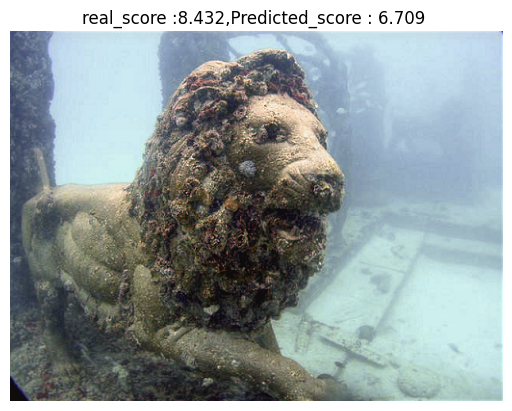

   Real Target  Predicted Target
0        8.432          6.709145


In [14]:
import matplotlib.pyplot as plt
import joblib
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Load the learned model
learned_estimator = joblib.load('learned_gpr_model.pkl')
# Load scaler
scaler = joblib.load('scaler.pkl')

# Path to the picture (ensure it's in the same directory as the script)
picture_to_show = 'ERI_BG_9_CBF.png'
# row 288 in mos corresponds to 286 in data-set 
input_data = real_data.iloc[286]  # Adjusted for zero-based indexing
input_target = target.iloc[286]  # Corresponding target
# Example: scaler = joblib.load('scaler.pkl') if saved previously
input_data_transformed = scaler.transform([input_data])  # Transform the input data

# Predict using the learned method
predicted_results = learned_estimator.predict(input_data_transformed)

# Combine the real targets and predicted results into a DataFrame
results = pd.DataFrame({
    'Real Target': [input_target],
    'Predicted Target': predicted_results
})

# Save the combined results to a CSV file
results_file = 'input_predictions.csv'
results.to_csv(results_file, index=False)

# Display the image 
# this is only for simple test , modify for bunch . 
image = plt.imread(picture_to_show)  # Read the image
plt.imshow(image)  # Show the image
plt.title(f'real_score :{input_target},Predicted_score :{predicted_results[0]: .3f} ')
plt.axis('off')  # Hide axes
plt.show()

print(results)


